In [1]:
# Section 1: Import libraries

from pathlib import Path
import json
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

import shap

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")
print("SHAP version:", shap.__version__)

Libraries imported successfully.
SHAP version: 0.51.0


In [2]:
# Section 2: Define project paths

from pathlib import Path

# Get the RiskWeave project root directory
PROJECT_ROOT = Path.cwd()

# If the notebook is running from the notebooks folder,
# move one level up to the project root.
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Define file paths
DATA_PATH = (
    PROJECT_ROOT / "data" / "processed" /
    "dengue_weather_weekly_25_districts.csv"
)

MODEL_PATH = (
    PROJECT_ROOT / "outputs" / "forecasting" /
    "riskweave_final_dengue_forecasting_model.joblib"
)

MANIFEST_PATH = (
    PROJECT_ROOT / "outputs" / "forecasting" /
    "riskweave_final_model_manifest.json"
)

# Create folder for SHAP outputs
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "explainability"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Check whether files exist
print("Project root:", PROJECT_ROOT)

print("\nProcessed dataset exists:", DATA_PATH.exists())
print("Final model exists:", MODEL_PATH.exists())
print("Model manifest exists:", MANIFEST_PATH.exists())

print("\nSHAP output folder:", OUTPUT_DIR)

Project root: c:\Users\Nethmi\Documents\GitHub\RiskWeave

Processed dataset exists: True
Final model exists: True
Model manifest exists: True

SHAP output folder: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\explainability


In [3]:
# Section 3: Load dataset and saved forecasting model

# Load the processed dengue and weather dataset
df = pd.read_csv(
    DATA_PATH,
    parse_dates=["week_start", "week_end"]
)

# Load the final model selected in Notebook 06
final_model = joblib.load(MODEL_PATH)

# Display dataset information
print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nNumber of districts:", df["district_key"].nunique())

print(
    "Date range:",
    df["week_start"].min(),
    "to",
    df["week_start"].max()
)

print("\nFinal forecasting model loaded successfully.")
print("Model type:", type(final_model).__name__)

# Display model manifest information
with open(MANIFEST_PATH, "r", encoding="utf-8") as file:
    model_manifest = json.load(file)

print("\nModel manifest loaded successfully.")

Dataset loaded successfully.
Dataset shape: (24775, 27)

Number of districts: 25
Date range: 2006-12-23 00:00:00 to 2025-12-13 00:00:00

Final forecasting model loaded successfully.
Model type: Pipeline

Model manifest loaded successfully.


In [4]:
# Section 4: Identify final model features

# Get feature names directly from the saved model
if hasattr(final_model, "feature_names_in_"):
    final_feature_cols = list(final_model.feature_names_in_)
else:
    raise ValueError(
        "The saved model does not contain feature_names_in_. "
        "We need to verify the feature names from Notebook 06."
    )

print("Number of model features:", len(final_feature_cols))

print("\nFeatures used by the final model:")

for i, feature in enumerate(final_feature_cols, start=1):
    print(f"{i}. {feature}")

Number of model features: 12

Features used by the final model:
1. district_key
2. dengue_current_period
3. dengue_lag_1
4. dengue_lag_2
5. dengue_lag_3
6. dengue_lag_4
7. dengue_lag_51
8. dengue_lag_52
9. dengue_rolling_mean_4
10. month
11. week_sin
12. week_cos


In [5]:
# Section 5: Recreate forecasting features

# Sort records by district and reporting week
df = df.sort_values(
    ["district_key", "week_start"]
).copy()

# Group dengue cases by district
grouped = df.groupby("district_key")["dengue_cases"]

# Current reporting period dengue cases
df["dengue_current_period"] = df["dengue_cases"]

# Historical dengue features
for lag in [1, 2, 3, 4, 51, 52]:
    df[f"dengue_lag_{lag}"] = grouped.shift(lag)

# Four-period rolling mean
df["dengue_rolling_mean_4"] = (
    df.groupby("district_key")["dengue_cases"]
    .transform(
        lambda x: x.rolling(
            window=4,
            min_periods=4
        ).mean()
    )
)

# Calendar features
df["month"] = df["week_start"].dt.month

# ISO reporting week
iso_week = df["week_start"].dt.isocalendar().week.astype(float)

# Cyclical week features
df["week_sin"] = np.sin(
    2 * np.pi * iso_week / 52
)

df["week_cos"] = np.cos(
    2 * np.pi * iso_week / 52
)

print("Forecasting features recreated successfully.")

print("\nFeature availability:")

for feature in final_feature_cols:
    print(
        feature,
        "->",
        df[feature].notna().sum(),
        "available values"
    )

Forecasting features recreated successfully.

Feature availability:
district_key -> 24775 available values
dengue_current_period -> 24775 available values
dengue_lag_1 -> 24750 available values
dengue_lag_2 -> 24725 available values
dengue_lag_3 -> 24700 available values
dengue_lag_4 -> 24675 available values
dengue_lag_51 -> 23500 available values
dengue_lag_52 -> 23475 available values
dengue_rolling_mean_4 -> 24700 available values
month -> 24775 available values
week_sin -> 24775 available values
week_cos -> 24775 available values


In [6]:
# Section 6: Prepare SHAP analysis dataset

# Create next reporting period target
df["target_next_period"] = (
    df.groupby("district_key")["dengue_cases"].shift(-1)
)

# Remove records with missing model features or target
model_data = df.dropna(
    subset=final_feature_cols + ["target_next_period"]
).copy()

# Sort chronologically
model_data = model_data.sort_values(
    ["week_start", "district_key"]
)

# Define the original test period from Notebook 06
TEST_START_DATE = pd.Timestamp("2023-02-11")

# Training-period background data
train_background_data = model_data[
    model_data["week_start"] < TEST_START_DATE
].copy()

# Held-out test data
test_data = model_data[
    model_data["week_start"] >= TEST_START_DATE
].copy()

# Prepare model inputs
X_background = train_background_data[final_feature_cols].copy()

X_test = test_data[final_feature_cols].copy()

y_test = test_data["target_next_period"].copy()

# Display dataset information
print("SHAP dataset preparation completed.")

print("\nComplete modelling dataset:", model_data.shape)

print("Training background dataset:", X_background.shape)

print("Test dataset:", X_test.shape)

print(
    "\nTest period:",
    test_data["week_start"].min(),
    "to",
    test_data["week_start"].max()
)

print("\nMissing values in background:", X_background.isna().sum().sum())

print("Missing values in test:", X_test.isna().sum().sum())

SHAP dataset preparation completed.

Complete modelling dataset: (23450, 39)
Training background dataset: (19750, 12)
Test dataset: (3700, 12)

Test period: 2023-02-11 00:00:00 to 2025-12-06 00:00:00

Missing values in background: 0
Missing values in test: 0


In [7]:
# Section 7: Verify saved model predictions

# Generate predictions using the saved final model
y_pred = final_model.predict(X_test)

# Calculate evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Model prediction verification completed.")

print("\nNumber of predictions:", len(y_pred))

print("Test MAE:", round(mae, 4))
print("Test RMSE:", round(rmse, 4))

# Compare against Notebook 06 final model results
print("\nNotebook 06 reference results:")
print("MAE: 12.3850")
print("RMSE: 28.8721")

Model prediction verification completed.

Number of predictions: 3700
Test MAE: 12.412
Test RMSE: 28.9545

Notebook 06 reference results:
MAE: 12.3850
RMSE: 28.8721


In [8]:
# Section 8: Investigate test dataset differences

print("Current Notebook 09 test information")

print("Test rows:", len(test_data))

print(
    "Unique test reporting weeks:",
    test_data["week_start"].nunique()
)

print(
    "Districts in test data:",
    test_data["district_key"].nunique()
)

print(
    "\nRows per district:"
)

print(
    test_data.groupby("district_key").size()
)

print("\nTest date range:")
print(test_data["week_start"].min())
print(test_data["week_start"].max())

Current Notebook 09 test information
Test rows: 3700
Unique test reporting weeks: 148
Districts in test data: 25

Rows per district:
district_key
ampara          148
anuradhapura    148
badulla         148
batticaloa      148
colombo         148
galle           148
gampaha         148
hambantota      148
jaffna          148
kalutara        148
kandy           148
kegalle         148
kilinochchi     148
kurunegala      148
mannar          148
matale          148
matara          148
moneragala      148
mullaitivu      148
nuwaraeliya     148
polonnaruwa     148
puttalam        148
ratnapura       148
trincomalee     148
vavuniya        148
dtype: int64

Test date range:
2023-02-11 00:00:00
2025-12-06 00:00:00


In [9]:
# Section 9: Identify missing test reporting week

# Get all unique reporting weeks from the original dataset
all_test_weeks = sorted(
    df.loc[
        df["week_start"] >= TEST_START_DATE,
        "week_start"
    ].unique()
)

# Get reporting weeks currently available in test data
available_test_weeks = sorted(
    test_data["week_start"].unique()
)

# Find missing weeks
missing_test_weeks = sorted(
    set(all_test_weeks) - set(available_test_weeks)
)

print("Expected test reporting weeks:", len(all_test_weeks))
print("Available test reporting weeks:", len(available_test_weeks))

print("\nMissing reporting weeks:")

for week in missing_test_weeks:
    print(pd.Timestamp(week).date())

print("\nNumber of missing weeks:", len(missing_test_weeks))

Expected test reporting weeks: 149
Available test reporting weeks: 148

Missing reporting weeks:
2025-12-13

Number of missing weeks: 1


In [10]:
# Section 10: Verify final reporting week

last_week = df["week_start"].max()

last_week_data = df[
    df["week_start"] == last_week
].copy()

print("Final reporting week:", last_week.date())

print("Number of district records:", len(last_week_data))

print(
    "Districts:",
    last_week_data["district_key"].nunique()
)

print(
    "Missing next-period targets:",
    last_week_data["target_next_period"].isna().sum()
)

print("\nVerification completed.")

Final reporting week: 2025-12-13
Number of district records: 25
Districts: 25
Missing next-period targets: 25

Verification completed.


In [11]:
# Section 11: Prepare SHAP background and test samples

# Set random seed for reproducibility
RANDOM_STATE = 42

# Select up to 100 background observations from training period
background_sample = X_background.sample(
    n=min(100, len(X_background)),
    random_state=RANDOM_STATE
)

# Select up to 100 observations from test period
test_sample = X_test.sample(
    n=min(100, len(X_test)),
    random_state=RANDOM_STATE
)

print("SHAP samples prepared successfully.")

print("\nBackground sample shape:", background_sample.shape)
print("Test explanation sample shape:", test_sample.shape)

print("\nBackground date range:")
print(
    train_background_data.loc[
        background_sample.index, "week_start"
    ].min(),
    "to",
    train_background_data.loc[
        background_sample.index, "week_start"
    ].max()
)

print("\nTest explanation sample date range:")
print(
    test_data.loc[
        test_sample.index, "week_start"
    ].min(),
    "to",
    test_data.loc[
        test_sample.index, "week_start"
    ].max()
)

SHAP samples prepared successfully.

Background sample shape: (100, 12)
Test explanation sample shape: (100, 12)

Background date range:
2008-04-12 00:00:00 to 2022-11-12 00:00:00

Test explanation sample date range:
2023-02-11 00:00:00 to 2025-11-29 00:00:00


In [14]:
# Section 12: Calculate SHAP values
# Handle categorical district names safely

# Create numerical copies for SHAP
background_encoded = background_sample.copy()
test_encoded = test_sample.copy()

# Create district mapping
district_categories = sorted(
    background_sample["district_key"].unique()
)

district_mapping = {
    district: index
    for index, district in enumerate(district_categories)
}

# Encode district names
background_encoded["district_key"] = (
    background_encoded["district_key"].map(district_mapping)
)

test_encoded["district_key"] = (
    test_encoded["district_key"].map(district_mapping)
)

# Convert to numerical arrays
background_array = background_encoded.to_numpy(dtype=float)
test_array = test_encoded.to_numpy(dtype=float)


# Prediction function
def model_predict(data):

    input_df = pd.DataFrame(
        data,
        columns=final_feature_cols
    )

    # Restore original district names
    input_df["district_key"] = (
        input_df["district_key"]
        .round()
        .astype(int)
        .map({v: k for k, v in district_mapping.items()})
    )

    if input_df["district_key"].isna().any():
        raise ValueError("Unknown district code encountered.")

    return final_model.predict(input_df)


# Create SHAP explainer
explainer = shap.PermutationExplainer(
    model_predict,
    background_array,
    feature_names=final_feature_cols
)

print("SHAP explainer created successfully.")

# Calculate SHAP values
shap_values = explainer(
    test_array,
    max_evals=2 * len(final_feature_cols) + 1
)

print("\nSHAP values calculated successfully.")

print("SHAP values shape:", shap_values.values.shape)

SHAP explainer created successfully.


PermutationExplainer explainer: 101it [00:11,  5.99it/s]                         


SHAP values calculated successfully.
SHAP values shape: (100, 12)


In [15]:
# Section 13: Calculate global SHAP feature importance

# Calculate mean absolute SHAP value for each feature
shap_importance = pd.DataFrame({
    "feature": final_feature_cols,
    "mean_absolute_shap": np.abs(
        shap_values.values
    ).mean(axis=0)
})

# Sort features by importance
shap_importance = shap_importance.sort_values(
    by="mean_absolute_shap",
    ascending=False
).reset_index(drop=True)

print("Global SHAP Feature Importance")
print("--------------------------------")

display(shap_importance)

Global SHAP Feature Importance
--------------------------------


,feature,mean_absolute_shap
0,dengue_current_period,24.095966
1,dengue_rolling_mean_4,9.804594
2,dengue_lag_1,6.069157
3,dengue_lag_51,1.481996
4,week_sin,1.251318
5,month,1.226073
6,dengue_lag_2,1.166091
7,week_cos,1.039123
8,dengue_lag_4,0.962885
9,dengue_lag_3,0.519616


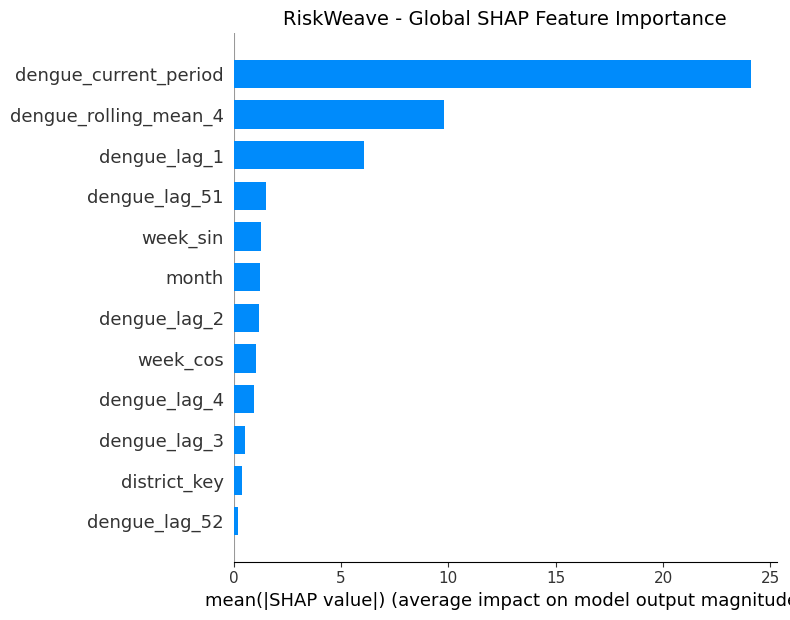

In [16]:
# Section 14: SHAP global feature importance plot

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values.values,
    test_array,
    feature_names=final_feature_cols,
    plot_type="bar",
    show=False
)

plt.title(
    "RiskWeave - Global SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

# Save the plot
plt.savefig(
    OUTPUT_DIR / "shap_global_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

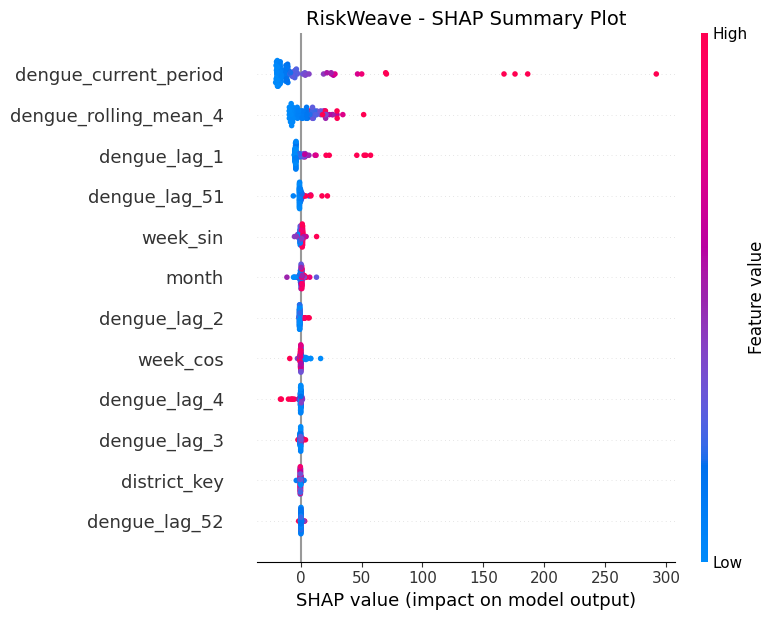

In [17]:
# Section 15: SHAP Beeswarm Summary Plot

plt.figure(figsize=(12, 8))

shap.summary_plot(
    shap_values.values,
    test_array,
    feature_names=final_feature_cols,
    show=False
)

plt.title(
    "RiskWeave - SHAP Summary Plot",
    fontsize=14
)

plt.tight_layout()

# Save the plot
plt.savefig(
    OUTPUT_DIR / "shap_beeswarm_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
# Section 16: Select an individual prediction

# Select the first observation in the SHAP test sample
sample_index = 0

# Get the selected observation
individual_data = test_sample.iloc[[sample_index]]

# Get its SHAP explanation
individual_shap = shap_values[sample_index]

# Generate model prediction
individual_prediction = final_model.predict(
    individual_data
)[0]

# Get actual next-period dengue cases
actual_index = individual_data.index[0]

actual_cases = test_data.loc[
    actual_index,
    "target_next_period"
]

print("Individual Prediction Explanation")
print("----------------------------------")

print("District:", individual_data["district_key"].iloc[0])

print(
    "Reporting week:",
    test_data.loc[actual_index, "week_start"].date()
)

print("Actual next-period cases:", actual_cases)

print(
    "Predicted next-period cases:",
    round(individual_prediction, 2)
)

print(
    "Base value:",
    round(float(np.asarray(individual_shap.base_values).squeeze()), 2)
)

Individual Prediction Explanation
----------------------------------
District: moneragala
Reporting week: 2023-11-25
Actual next-period cases: 46.0
Predicted next-period cases: 14.37
Base value: 37.87


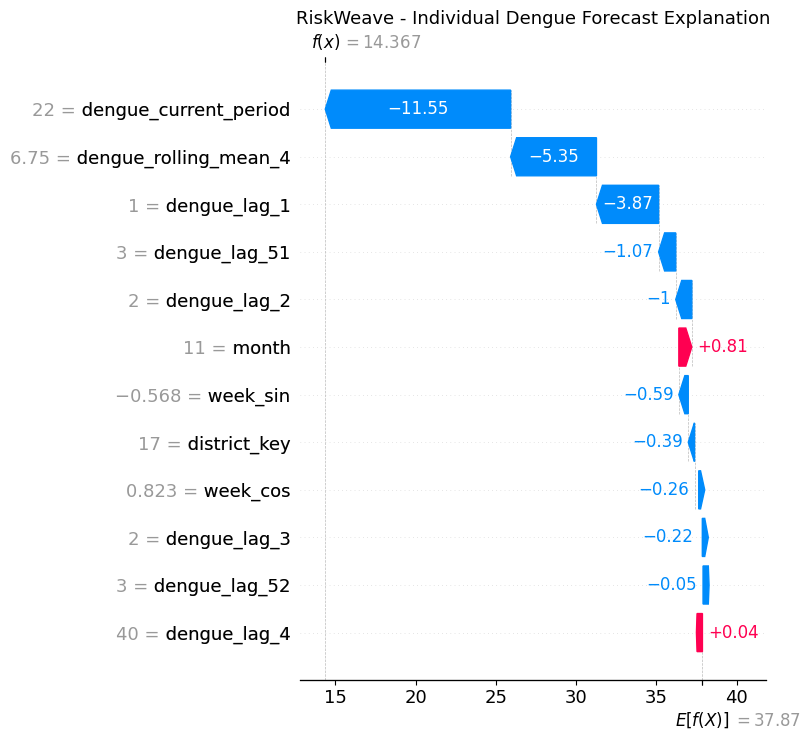

In [19]:
# Section 17: Individual SHAP waterfall plot

plt.figure(figsize=(10, 7))

shap.plots.waterfall(
    individual_shap,
    max_display=12,
    show=False
)

plt.title(
    "RiskWeave - Individual Dengue Forecast Explanation",
    fontsize=13
)

plt.tight_layout()

# Save the plot
plt.savefig(
    OUTPUT_DIR / "shap_individual_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# Section 18: Save SHAP results

# Save global feature importance
shap_importance.to_csv(
    OUTPUT_DIR / "shap_global_feature_importance.csv",
    index=False
)

# Save SHAP values for all explained test observations
shap_values_df = pd.DataFrame(
    shap_values.values,
    columns=final_feature_cols,
    index=test_sample.index
)

shap_values_df.to_csv(
    OUTPUT_DIR / "shap_test_values.csv"
)

# Save individual prediction explanation
individual_explanation = pd.DataFrame({
    "feature": final_feature_cols,
    "feature_value": test_sample.iloc[0].values,
    "shap_value": shap_values.values[0]
})

individual_explanation.to_csv(
    OUTPUT_DIR / "shap_individual_explanation.csv",
    index=False
)

print("SHAP results saved successfully.")

print("\nSaved files:")
for file in OUTPUT_DIR.iterdir():
    print(file.name)

SHAP results saved successfully.

Saved files:
colombo_shap_waterfall.png
gampaha_shap_waterfall.png
jaffna_shap_waterfall.png
kandy_shap_waterfall.png
shap_beeswarm_summary.png
shap_global_feature_importance.csv
shap_global_feature_importance.png
shap_individual_explanation.csv
shap_individual_waterfall.png
shap_summary_beeswarm.png
shap_test_values.csv


In [21]:
# Section 19: Create SHAP methodology manifest

manifest = {
    "project": "RiskWeave",
    "notebook": "09_shap_explainability.ipynb",
    "analysis": "SHAP Explainability",

    "model": {
        "model_file": "riskweave_final_dengue_forecasting_model.joblib",
        "model_type": type(final_model).__name__,
        "selected_features": final_feature_cols,
        "feature_count": len(final_feature_cols),
        "weather_features_used": False
    },

    "dataset": {
        "source_file": DATA_PATH.name,
        "district_count": int(df["district_key"].nunique()),
        "background_observations": len(background_sample),
        "test_observations_explained": len(test_sample),
        "test_period_start": str(test_data["week_start"].min().date()),
        "test_period_end": str(test_data["week_start"].max().date())
    },

    "shap_method": {
        "explainer": "PermutationExplainer",
        "background_sample_size": len(background_sample),
        "test_sample_size": len(test_sample),
        "random_state": RANDOM_STATE,
        "max_evals": 2 * len(final_feature_cols) + 1,
        "district_encoding": "Numerical category mapping for SHAP calculation only"
    },

    "interpretation_limitations": [
        "SHAP explains model behaviour, not causality.",
        "Explanations are based on sampled test observations.",
        "District numerical encoding introduces an artificial ordering.",
        "Weather variables are not included in the final forecasting model.",
        "Correlated dengue history features may share contributions.",
        "SHAP results do not establish dengue outbreak confirmation."
    ]
}

manifest_path = OUTPUT_DIR / "shap_explainability_manifest.json"

with open(manifest_path, "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=4)

print("SHAP methodology manifest saved successfully.")
print("Manifest path:", manifest_path)

SHAP methodology manifest saved successfully.
Manifest path: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\explainability\shap_explainability_manifest.json


In [22]:
# Section 20: Final output verification

required_outputs = [
    "shap_global_feature_importance.csv",
    "shap_global_feature_importance.png",
    "shap_beeswarm_summary.png",
    "shap_individual_explanation.csv",
    "shap_individual_waterfall.png",
    "shap_test_values.csv",
    "shap_explainability_manifest.json"
]

print("RiskWeave - SHAP Output Audit")
print("=" * 45)

all_files_exist = True

for filename in required_outputs:

    file_path = OUTPUT_DIR / filename

    exists = file_path.exists()

    print(
        f"{filename}:",
        "EXISTS" if exists else "MISSING"
    )

    if not exists:
        all_files_exist = False

print("\n" + "=" * 45)

if all_files_exist:
    print("All required SHAP outputs verified.")
else:
    print("Some SHAP outputs are missing.")

RiskWeave - SHAP Output Audit
shap_global_feature_importance.csv: EXISTS
shap_global_feature_importance.png: EXISTS
shap_beeswarm_summary.png: EXISTS
shap_individual_explanation.csv: EXISTS
shap_individual_waterfall.png: EXISTS
shap_test_values.csv: EXISTS
shap_explainability_manifest.json: EXISTS

All required SHAP outputs verified.
